# Коммерческий успех по всем признакам приложения

## 0. Задача

Регрессия. Коммерческий успех — число отзывов `Reviews`. Предсказываем его по всем остальным признакам таблицы: категория, оценка, размер, установки, тип, цена, возрастной рейтинг, жанр, год обновления, версия Android.

Название приложения — это идентификатор, в модель его не берём. Текущая версия приложения — разнородный текст, из него не получается устойчивый признак. Само число отзывов является целью, поэтому в признаки оно не входит.

## 1. Чтение данных

In [1]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler

%matplotlib inline
plt.rcParams["font.family"] = "Arial"
plt.rcParams["axes.unicode_minus"] = False

DATA_PATH = Path("data/googleplaystore.csv")
if not DATA_PATH.exists():
    for candidate in (Path("googleplaystore.csv"), Path.home() / "Downloads" / "googleplaystore.csv"):
        if candidate.exists():
            DATA_PATH = candidate
            break
if not DATA_PATH.exists():
    raise FileNotFoundError("Укажите путь к googleplaystore.csv в DATA_PATH")

raw = pd.read_csv(DATA_PATH)
print(raw.shape)
raw.head(3)

(10841, 13)


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up


## 2. Обучающая и тестовая выборки

Убираем битую строку и повторные названия. Размер, установки, цену и версию Android переводим в числа. Цель — `log(1 + Reviews)`: у отзывов хвост до десятков миллионов.

75% — обучение, 25% — тест. Медианы для пропусков дальше считаем только по обучению.

In [2]:
def size_to_mb(value):
    text = str(value).strip()
    if text.endswith("M"):
        return float(text[:-1])
    if text.endswith("k"):
        return float(text[:-1]) / 1024
    return np.nan


def installs_to_number(value):
    return float(str(value).replace(",", "").replace("+", ""))


def android_major(value):
    text = str(value).strip().replace("W", "")
    if text in ("nan", "Varies with device"):
        return np.nan
    try:
        return float(text.split(" ")[0].split(".")[0])
    except ValueError:
        return np.nan


df = raw[raw["Category"] != "1.9"].drop_duplicates("App").copy()
df = df[df["Type"].isin(["Free", "Paid"])]
df["Rating"] = pd.to_numeric(df["Rating"], errors="coerce")
df["Reviews"] = pd.to_numeric(df["Reviews"], errors="coerce")
df["Size_MB"] = df["Size"].map(size_to_mb)
df["Installs_log"] = np.log1p(df["Installs"].map(installs_to_number))
df["Price_log"] = np.log1p(df["Price"].str.replace("$", "", regex=False).astype(float))
df["Year"] = pd.to_datetime(df["Last Updated"], errors="coerce").dt.year.astype(float)
df["Android"] = df["Android Ver"].map(android_major)
df["Free"] = (df["Type"] == "Free").astype(float)
df["Content"] = df["Content Rating"].astype(str)
df["Genre"] = df["Genres"].astype(str).str.split(";").str[0]
df["y"] = np.log1p(df["Reviews"])
df = df.dropna(subset=["Reviews", "Installs_log", "Price_log", "Year", "Category", "Content", "Genre"])

num_cols = ["Rating", "Size_MB", "Installs_log", "Price_log", "Year", "Android", "Free"]
cat_cols = ["Category", "Content", "Genre"]

train, test = train_test_split(df, test_size=0.25, random_state=42)
train = train.copy()
test = test.copy()
print("строк:", len(df), ", обучение:", len(train), ", тест:", len(test))
print("бесплатных / платных:", int(df["Free"].sum()), "/", int((df["Free"] == 0).sum()))

строк: 9658 , обучение: 7243 , тест: 2415
бесплатных / платных: 8902 / 756


## 3. Характеристики и графики

Reviews                     Size_MB               Rating               \
           mean  median         std    mean median    std   mean median   std   
Type                                                                            
Free  214735.07  1288.0  1691275.20   20.30   12.0  21.61   4.17    4.3  0.54   
Paid    9716.53    89.5   102619.57   19.69   10.5  22.13   4.25    4.4  0.57   

     Price_log               
          mean median   std  
Type                         
Free       0.0   0.00  0.00  
Paid       1.6   1.38  1.01

,Rating,Size_MB,Installs_log,Price_log,Year,Android,Free,y
Rating,1.000,0.071,0.090,0.022,0.131,0.059,-0.040,0.185
Size_MB,0.071,1.000,0.293,-0.010,0.201,0.130,0.008,0.332
Installs_log,0.090,0.293,1.000,-0.191,0.161,0.013,0.227,0.958
Price_log,0.022,-0.010,-0.191,1.000,-0.116,-0.073,-0.836,-0.120
Year,0.131,0.201,0.161,-0.116,1.000,0.504,0.162,0.167
Android,0.059,0.130,0.013,-0.073,0.504,1.000,0.103,0.012
Free,-0.040,0.008,0.227,-0.836,0.162,0.103,1.000,0.145
y,0.185,0.332,0.958,-0.120,0.167,0.012,0.145,1.000


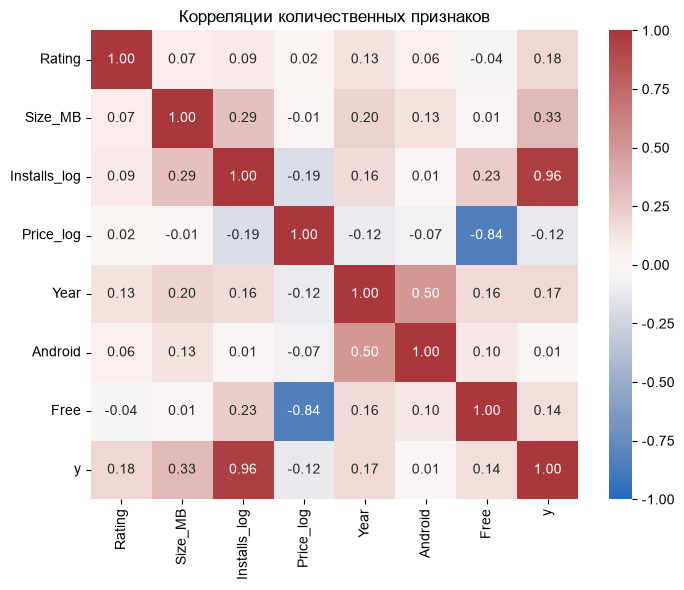

In [3]:
display(train.groupby("Type")[["Reviews", "Size_MB", "Rating", "Price_log"]].agg(["mean", "median", "std"]).round(2))

corr = train[num_cols + ["y"]].corr()
display(corr.round(3))

fig, ax = plt.subplots(figsize=(7.2, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, ax=ax)
ax.set_title("Корреляции количественных признаков")
fig.tight_layout()

Итог. Число установок почти повторяет число отзывов: корреляция 0.96. Дальше по силе идут размер (0.33), оценка (0.19), год обновления (0.17) и бесплатность (0.15). Цена связана слабо и отрицательно (−0.12). Версия Android с успехом не связана (0.01). Цена и признак «бесплатное» дублируют друг друга: корреляция −0.84, у бесплатного приложения цена равна нулю.

## 4. Выбросы

Установки и отзывы доходят до десятков и сотен миллионов. Это популярные приложения, не ошибки записи. Удалять их не будем: логарифм уже сжал хвост. Размер не больше 100 МБ, оценка лежит от 1 до 5. Битая строка с категорией `1.9` отброшена в пункте 2.

In [4]:
print("отзывы, максимум:", int(train["Reviews"].max()))
print("установки, log-максимум:", round(train["Installs_log"].max(), 2))
print("размер, МБ: от", round(train["Size_MB"].min(), 3), "до", train["Size_MB"].max())
print("оценка: от", train["Rating"].min(), "до", train["Rating"].max())

отзывы, максимум: 69119316
установки, log-максимум: 20.72
размер, МБ: от 0.008 до 100.0
оценка: от 1.0 до 5.0


## 5. Пропуски

Пропуски есть в оценке, размере (`Varies with device`) и версии Android. Заполняем медианой обучающей выборки и ту же медиану подставляем в тест.

In [5]:
print("пропуски в обучении:")
print(train[num_cols].isna().sum())
medians = {}
for col in num_cols:
    medians[col] = train[col].median()
    train[col] = train[col].fillna(medians[col])
    test[col] = test[col].fillna(medians[col])
print("пропусков осталось:", int(pd.concat([train[num_cols], test[num_cols]]).isna().sum().sum()))

пропуски в обучении:
Rating          1104
Size_MB          915
Installs_log       0
Price_log          0
Year               0
Android          733
Free               0
dtype: int64
пропусков осталось: 0


## 6. Категориальные признаки

Категория, возрастной рейтинг и жанр не имеют порядка. Кодируем их индикаторами, один уровень каждого признака оставляем базовым. Тип приложения уже записан числом `Free`: 1 — бесплатное, 0 — платное. Составной жанр обрезаем до части до точки с запятой.

In [9]:
def design_matrix(train_df, test_df):
    train_cat = pd.get_dummies(train_df[cat_cols], drop_first=True)
    test_cat = pd.get_dummies(test_df[cat_cols], drop_first=True)
    test_cat = test_cat.reindex(columns=train_cat.columns, fill_value=0)
    names = num_cols + list(train_cat.columns)
    x_train = np.hstack([train_df[num_cols].to_numpy(float), train_cat.to_numpy(float)])
    x_test = np.hstack([test_df[num_cols].to_numpy(float), test_cat.to_numpy(float)])
    return x_train, x_test, names


X_train_raw, X_test_raw, feature_names = design_matrix(train, test)
print("признаков:", len(feature_names))

признаков: 91


## 7. Нормализация

Ближайшие соседи сравнивают приложения по расстоянию. Установки, цена и год измерены в разных шкалах, поэтому количественные столбцы приводим к среднему 0 и стандартному отклонению 1. Масштаб считаем по обучению. Индикаторы категорий оставляем нулями и единицами.

In [7]:
scaler = StandardScaler()
X_train = X_train_raw.copy()
X_test = X_test_raw.copy()
n_num = len(num_cols)
X_train[:, :n_num] = scaler.fit_transform(X_train_raw[:, :n_num])
X_test[:, :n_num] = scaler.transform(X_test_raw[:, :n_num])
y_train = train["y"].to_numpy()
y_test = test["y"].to_numpy()
print("средние количественных признаков:", np.round(X_train[:, :n_num].mean(0), 5))

средние количественных признаков: [ 0.  0. -0. -0. -0. -0.  0.]


## 8–9. Ближайшие соседи, ошибка, выбор k

Цель — число, поэтому берём регрессию k ближайших соседей. Ошибка — средний квадрат отклонения по `log(1 + Reviews)`. Матрицы рассогласования нет: это регрессия.

k выбираем кросс-валидацией на обучении. Рядом печатаем ошибку константы «всем среднее» и ошибку той же модели без столбца установок: установки почти совпадают с целью, и это нужно видеть отдельно.

лучшее k: 7
ошибка на обучении: 1.516
ошибка на тесте: 1.98
ошибка константы на тесте: 17.752
доля объяснённой дисперсии на тесте: 0.888
без установок: k = 11 , ошибка на тесте = 11.013 , доля дисперсии = 0.38
корреляция установок и log(отзывы): 0.958


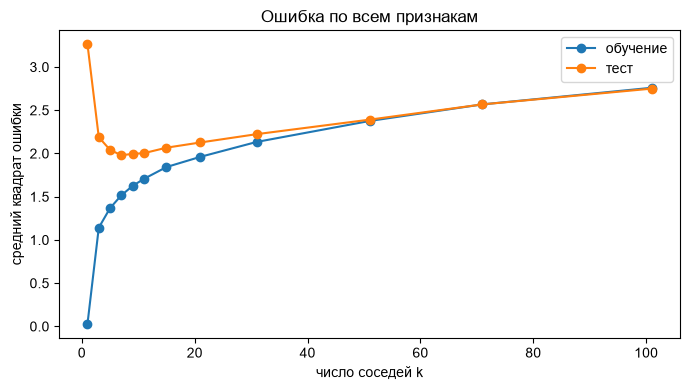

In [8]:
ks = [1, 3, 5, 7, 9, 11, 15, 21, 31, 51, 71, 101]
err_train, err_test = [], []
for k in ks:
    model = KNeighborsRegressor(n_neighbors=k)
    model.fit(X_train, y_train)
    err_train.append(np.mean((y_train - model.predict(X_train)) ** 2))
    err_test.append(np.mean((y_test - model.predict(X_test)) ** 2))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ks, err_train, marker="o", label="обучение")
ax.plot(ks, err_test, marker="o", label="тест")
ax.set_xlabel("число соседей k")
ax.set_ylabel("средний квадрат ошибки")
ax.set_title("Ошибка по всем признакам")
ax.legend()
fig.tight_layout()

search = GridSearchCV(
    KNeighborsRegressor(),
    {"n_neighbors": ks},
    scoring="neg_mean_squared_error",
    cv=5,
    n_jobs=1,
)
search.fit(X_train, y_train)
best_k = search.best_params_["n_neighbors"]
mse_train = np.mean((y_train - search.predict(X_train)) ** 2)
mse_test = np.mean((y_test - search.predict(X_test)) ** 2)
mse_const = np.mean((y_test - y_train.mean()) ** 2)

installs_idx = num_cols.index("Installs_log")
keep = [i for i in range(X_train.shape[1]) if i != installs_idx]
search_wo = GridSearchCV(
    KNeighborsRegressor(),
    {"n_neighbors": ks},
    scoring="neg_mean_squared_error",
    cv=5,
    n_jobs=1,
)
search_wo.fit(X_train[:, keep], y_train)
mse_wo = np.mean((y_test - search_wo.predict(X_test[:, keep])) ** 2)

print("лучшее k:", best_k)
print("ошибка на обучении:", round(mse_train, 3))
print("ошибка на тесте:", round(mse_test, 3))
print("ошибка константы на тесте:", round(mse_const, 3))
print("доля объяснённой дисперсии на тесте:", round(1 - mse_test / mse_const, 3))
print("без установок: k =", search_wo.best_params_["n_neighbors"],
      ", ошибка на тесте =", round(mse_wo, 3),
      ", доля дисперсии =", round(1 - mse_wo / mse_const, 3))
print("корреляция установок и log(отзывы):", round(train[["Installs_log", "y"]].corr().iloc[0, 1], 3))

## 13. Выводы

По всем признакам ближайшие соседи предсказывают число отзывов хорошо. Лучшее k = 7. Ошибка на тесте 1.98 против 17.75 у константы, объясняется около 89% разброса.

Почти весь этот результат даёт число установок: корреляция с log(отзывы) равна 0.96. Без установок ошибка на тесте вырастает до 11.03, и остаётся около 38% разброса. Установки и отзывы измеряют одну популярность.

Из остальных признаков заметны размер, оценка, год обновления и бесплатность. В обучении медиана отзывов 1288 у бесплатных и 90 у платных. Более дорогое приложение комментируют реже. Версия Android на число отзывов не влияет. Категория, жанр и возрастной рейтинг входят в расстояние между приложениями, но не перекрывают роль установок.